In [59]:
# Environment and path setup is handled in the next cell.


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [60]:
import math
import sys
import os

try:
    from google.colab import drive
    drive.mount('/content/drive')
    utils_path = "/content/drive/MyDrive/ColabProject/utils"
    print("Environment: Google Colab")
except ImportError:
    utils_path = os.path.abspath(os.path.join(os.getcwd(), "..", "utils"))
    print("Environment: Local")

if utils_path not in sys.path:
    sys.path.append(utils_path)

print(f"Utils path: {utils_path}")
print(f"Files available: {os.listdir(utils_path)}")

Available files in utils: ['pruning.py', 'utility_reset.py', 'filtered_paths.py', '__pycache__', 'region_checks.py', 'intersection_utils.py', 'point_generator.py', 'path_analysis.py', 'plotting.py', 'nextSteps.txt', 'test_all_subregions.py', 'test_sticks_in_subregions.ipynb', 'test_paths_in_subregions.ipynb', 'test_new_data_sctructures.ipynb', 'PiaNo.ipynb']


In [61]:
from point_generator import *
from region_checks import *
from intersection_utils import *
from path_analysis import *
from plotting import *
from pruning import *
from filtered_paths import *
from utility_reset import *
#from predefined_networks import *
from tests import *

# **Executing the Experiment**

In [62]:
# Main variables
a = 0.70
N = 30

points_1 = []
points_2 = []
angles = []
graph = [] #edges
nodes = []
intersected_line_1 = []
intersected_line_2 = []
intersections_points = []
all_connected_nodes = []
solutions = []
A = []
L = []
paths = []

In [63]:
generate_points(N, points_1, points_2, angles, a)

In [64]:
intersections_points, intersected_line_1, intersected_line_2, graph = identify_intersections(points_1, points_2, intersections_points, intersected_line_1, intersected_line_2, graph, angles, a, N)

In [65]:
len(intersections_points)

65

In [66]:
boundary_condition_source = []
boundary_condition_drain = []

In [67]:
for i in range(len(intersections_points)):
  if intersections_points[i][0] < 0.1:
    boundary_condition_source.append(i)
  elif intersections_points[i][0] > 0.9:
    boundary_condition_drain.append(i)

In [68]:
print("Number of identified intersection points =", len(intersections_points))
print("In the source contact region =", len(boundary_condition_source))
print("In the drain contact region =", len(boundary_condition_drain))
print(boundary_condition_source)

Number of identified intersection points = 65
In the source contact region = 8
In the drain contact region = 6
[13, 15, 19, 21, 22, 23, 24, 27]


In [78]:
 print(boundary_condition_source)
 print(boundary_condition_drain)

[13, 15, 19, 21, 22, 23, 24, 27]
[0, 9, 10, 45, 56, 57]


In [69]:
path_nodes, path_pairs_of_lines, path_pairs_of_edges, all_path_perc = [], [], [], []

In [70]:
for i in boundary_condition_source:
  do_not_check = 0
  number_path = len(all_connected_nodes)
  for k in range(0,number_path):
    if i in all_connected_nodes[k]:
      do_not_check = 1
  if do_not_check == 0:
    print(f"Path number = {number_path}")
    print(f"node = {i}")
    start_node = i
    nodes, pair_of_lines, pair_of_edges, path_perc = find_path(intersections_points, graph, start_node)
    path_nodes.append(nodes)
    path_pairs_of_lines.append(pair_of_lines)
    path_pairs_of_edges.append(pair_of_edges,)
    all_path_perc.append(path_perc)
  # print(f"All nodes = {all_connected_nodes}")
  # print(f"All lines = {pair_of_lines}")

Path number = 0
node = 13
valor de queue antes = deque([13])
valor de queue depois = deque([])
nós visitados {13}
valor de target edge = (8, 13)
valor de path_pairs_of_lines = [(8, 13)]
valor do i = 12
valor do current node = 13
valor da queue após append = deque([12])
valor do path_pairs_of_nodes[13, 12]
valor do path_pairs_of_lines = [(8, 13), (8, 2)]
valor do path_pairs_of_edges = [(13, 12)]
valor do i = 14
valor do current node = 13
valor da queue após append = deque([12, 14])
valor do path_pairs_of_nodes[13, 12, 14]
valor do path_pairs_of_lines = [(8, 13), (8, 2), (8, 24)]
valor do path_pairs_of_edges = [(13, 12), (13, 14)]
valor do i = 15
valor do current node = 13
valor da queue após append = deque([12, 14, 15])
valor do path_pairs_of_nodes[13, 12, 14, 15]
valor do path_pairs_of_lines = [(8, 13), (8, 2), (8, 24), (8, 25)]
valor do path_pairs_of_edges = [(13, 12), (13, 14), (13, 15)]
valor do i = 19
valor do current node = 13
valor da queue após append = deque([12, 14, 15, 19])
v

In [71]:
print(path_nodes) #create list of the corresponding pairs of edges
print(path_pairs_of_lines) #check what it is
print(path_pairs_of_edges) #create list of the corresponding nodes
print(all_path_perc)

[[13, 12, 14, 15, 19, 21, 27, 37, 42, 4, 18, 34, 58, 60, 20, 23, 40, 50, 59, 64, 24, 17, 36, 47, 22, 35, 38, 39, 48, 29, 41, 49, 55, 63, 1, 6, 28, 43, 46, 52, 61, 32, 51, 62, 31, 2, 3, 5, 16, 26, 30, 53, 54, 56, 57, 7, 8, 9, 10, 11, 44, 25, 45, 0, 33], [15, 12, 13, 14, 24, 27, 4, 18, 34, 58, 60, 19, 21, 37, 42, 20, 23, 40, 50, 59, 64, 22, 1, 6, 28, 41, 43, 46, 52, 61, 17, 36, 47, 35, 38, 39, 48, 32, 51, 62, 63, 29, 49, 55, 31, 2, 3, 5, 7, 8, 9, 10, 11, 53, 16, 26, 30, 44, 54, 56, 57, 0, 33, 45, 25], [19, 13, 17, 18, 20, 21, 27, 36, 37, 42, 47, 12, 14, 15, 1, 2, 3, 5, 4, 34, 58, 60, 23, 40, 50, 59, 64, 22, 24, 35, 38, 39, 48, 29, 41, 49, 55, 63, 31, 46, 51, 6, 28, 43, 52, 61, 11, 44, 7, 8, 9, 10, 53, 32, 62, 16, 26, 30, 54, 56, 57, 0, 33, 45, 25], [21, 13, 19, 22, 23, 24, 27, 37, 42, 12, 14, 15, 17, 18, 20, 36, 47, 38, 40, 50, 58, 59, 64, 34, 35, 39, 48, 29, 41, 49, 55, 63, 4, 60, 1, 2, 3, 5, 31, 46, 51, 6, 28, 43, 52, 61, 32, 62, 16, 26, 30, 53, 54, 56, 57, 11, 44, 7, 8, 9, 10, 25, 45,

In [72]:
# Create list of edges corresponding to nodes of each path in the generated random network
path_edges = []

print("🔍 CREATING path_edges STRUCTURE - Random network edges for each path:")
print(f"   Generated network: {N} lines, {len(intersections_points)} intersection points, {len(graph)} edges")

for path_idx, nodes_in_path in enumerate(path_nodes):
    edges_in_path = []
    print(f"\n   Processing Path {path_idx + 1}: {nodes_in_path}")

    # For each consecutive pair of nodes in the path, find the edge that connects them in the network
    for i in range(len(nodes_in_path) - 1):
        node1 = nodes_in_path[i]
        node2 = nodes_in_path[i + 1]

        # Search for the edge that connects node1 and node2 in the random network graph
        edge_found = None
        for edge_idx, edge in enumerate(graph):
            # Check if the edge connects the two nodes (in either direction)
            if (edge[0] == node1 and edge[1] == node2) or (edge[0] == node2 and edge[1] == node1):
                edge_found = edge_idx
                print(f"     Nodes {node1}↔{node2} connected by edge {edge_idx}: {edge}")
                break

        if edge_found is not None:
            edges_in_path.append(edge_found)
        else:
            print(f"     ⚠ WARNING: No edge found connecting nodes {node1} and {node2}")

    path_edges.append(edges_in_path)
    print(f"     Path edges: {edges_in_path}")

print(f"\n✅ path_edges STRUCTURE created:")
print(f"   Edges corresponding to nodes of each path in the random network:")
for i, edges in enumerate(path_edges):
    print(f"   Path {i+1}: {edges}")
print()

# Create list of nodes corresponding to edge pairs from the random network
edge_nodes = []

print("🔍 CREATING edge_nodes STRUCTURE - Random network nodes for each edge pair:")
print(f"   Using edge pairs identified in the network: path_pairs_of_edges")

for path_idx, pairs_of_edges in enumerate(path_pairs_of_edges):
    nodes_from_edges = []
    print(f"\n   Processing Path {path_idx + 1} - Edge pairs: {pairs_of_edges}")

    for pair_idx, edge_pair in enumerate(pairs_of_edges):
        # edge_pair contains two edge indices from the random network
        edge1_idx, edge2_idx = edge_pair
        print(f"     Pair {pair_idx + 1}: Edges {edge1_idx} and {edge2_idx}")

        # Check if the indices are valid in the random network graph
        if edge1_idx >= len(graph) or edge2_idx >= len(graph):
            print(f"       ⚠ WARNING: Invalid edge indices - graph has {len(graph)} edges")
            continue

        # Get the nodes from the corresponding edges in the network
        edge1_nodes = graph[edge1_idx]
        edge2_nodes = graph[edge2_idx]
        print(f"       Edge {edge1_idx}: nodes {edge1_nodes}")
        print(f"       Edge {edge2_idx}: nodes {edge2_nodes}")

        # Find the common node between the two edges (network intersection point)
        common_node = None
        for node in edge1_nodes:
            if node in edge2_nodes:
                common_node = node
                break

        if common_node is not None:
            nodes_from_edges.append(common_node)
            print(f"       Common node found: {common_node}")

            # Check if the common node exists in the network intersection points
            if common_node < len(intersections_points):
                coord = intersections_points[common_node]
                print(f"       Network coordinate: ({coord[0]:.3f}, {coord[1]:.3f})")
            else:
                print(f"       ⚠ WARNING: Node {common_node} not found in intersection points")
        else:
            print(f"       ⚠ WARNING: No common node found between edges {edge1_idx} and {edge2_idx}")

    edge_nodes.append(nodes_from_edges)
    print(f"     Path nodes derived from edge pairs: {nodes_from_edges}")

print(f"\n✅ edge_nodes STRUCTURE created:")
print(f"   Nodes corresponding to edge pairs from the random network:")
for i, nodes in enumerate(edge_nodes):
    print(f"   Path {i+1}: {nodes}")

# Verification of correspondence between network structures
print(f"\n🔍 VERIFICATION OF CORRESPONDENCE WITH RANDOM NETWORK:")
print(f"   Network parameters: a={a}, N={N}")
print(f"   Generated intersection points: {len(intersections_points)}")
print(f"   Graph edges: {len(graph)}")
print(f"   Found paths: {len(path_nodes)}")

for i in range(len(path_nodes)):
    print(f"\n   Path {i+1} in random network:")
    print(f"     • path_nodes: {path_nodes[i] if i < len(path_nodes) else 'N/A'}")
    print(f"     • path_edges: {path_edges[i] if i < len(path_edges) else 'N/A'}")
    print(f"     • path_pairs_of_edges: {path_pairs_of_edges[i] if i < len(path_pairs_of_edges) else 'N/A'}")
    print(f"     • edge_nodes: {edge_nodes[i] if i < len(edge_nodes) else 'N/A'}")

    # Check consistency
    if i < len(path_nodes) and i < len(edge_nodes):
        nodes_match = set(path_nodes[i]) == set(edge_nodes[i])
        status = "✓ CONSISTENT" if nodes_match else "⚠ INCONSISTENT"
        print(f"     • Node correspondence: {status}")

print()

🔍 CREATING path_edges STRUCTURE - Random network edges for each path:
   Generated network: 30 lines, 65 intersection points, 65 edges

   Processing Path 1: [13, 12, 14, 15, 19, 21, 27, 37, 42, 4, 18, 34, 58, 60, 20, 23, 40, 50, 59, 64, 24, 17, 36, 47, 22, 35, 38, 39, 48, 29, 41, 49, 55, 63, 1, 6, 28, 43, 46, 52, 61, 32, 51, 62, 31, 2, 3, 5, 16, 26, 30, 53, 54, 56, 57, 7, 8, 9, 10, 11, 44, 25, 45, 0, 33]
     ⚠ WARNING: No edge found connecting nodes 13 and 12
     Nodes 12↔14 connected by edge 26: (12, 14)
     ⚠ WARNING: No edge found connecting nodes 14 and 15
     ⚠ WARNING: No edge found connecting nodes 15 and 19
     ⚠ WARNING: No edge found connecting nodes 19 and 21
     Nodes 21↔27 connected by edge 45: (21, 27)
     ⚠ WARNING: No edge found connecting nodes 27 and 37
     ⚠ WARNING: No edge found connecting nodes 37 and 42
     ⚠ WARNING: No edge found connecting nodes 42 and 4
     ⚠ WARNING: No edge found connecting nodes 4 and 18
     ⚠ WARNING: No edge found connecting 

In [73]:
# COMPLETE VALIDATION OF CORRESPONDENCE WITH RANDOM NETWORK
print("=" * 80)
print("VALIDATION OF DATA STRUCTURES WITH GENERATED RANDOM NETWORK")
print("=" * 80)

# 1. Validate network parameters
print(f"🌐 RANDOM NETWORK PARAMETERS:")
print(f"   • Parameter a: {a}")
print(f"   • Number of lines N: {N}")
print(f"   • Generated points (points_1): {len(points_1)}")
print(f"   • Generated points (points_2): {len(points_2)}")
print(f"   • Generated angles: {len(angles)}")

# 2. Validate intersections
print(f"\n🔗 NETWORK INTERSECTIONS:")
print(f"   • Identified intersection points: {len(intersections_points)}")
print(f"   • Intersected lines (type 1): {len(intersected_line_1)}")
print(f"   • Intersected lines (type 2): {len(intersected_line_2)}")
print(f"   • Graph edges: {len(graph)}")

# 3. Validate boundary conditions
print(f"\n🎯 BOUNDARY CONDITIONS:")
print(f"   • Source nodes (x < 0.1): {boundary_condition_source}")
print(f"   • Drain nodes (x > 0.9): {boundary_condition_drain}")

# Check if source/drain nodes exist in intersection points
source_valid = all(i < len(intersections_points) for i in boundary_condition_source)
drain_valid = all(i < len(intersections_points) for i in boundary_condition_drain)
print(f"   • Valid sources: {'✓' if source_valid else '✗'}")
print(f"   • Valid drains: {'✓' if drain_valid else '✗'}")

# 4. Validate found paths
print(f"\n🛤️ NETWORK PATHS:")
print(f"   • Total found paths: {len(path_nodes)}")

for i in range(len(path_nodes)):
    print(f"\n   Path {i+1}:")
    nodes = path_nodes[i] if i < len(path_nodes) else []
    edges = path_edges[i] if i < len(path_edges) else []
    pairs = path_pairs_of_edges[i] if i < len(path_pairs_of_edges) else []
    edge_n = edge_nodes[i] if i < len(edge_nodes) else []
    perc = all_path_perc[i] if i < len(all_path_perc) else None

    print(f"     • Nodes: {nodes}")
    print(f"     • Edges: {edges}")
    print(f"     • Edge pairs: {pairs}")
    print(f"     • Pair nodes: {edge_n}")
    print(f"     • Percolating: {'YES' if perc else 'NO' if perc is not None else 'N/A'}")

    # Specific validations
    # 1. Do all nodes exist in intersection points?
    nodes_valid = all(node < len(intersections_points) for node in nodes)
    print(f"     • Valid nodes in network: {'✓' if nodes_valid else '✗'}")

    # 2. Do all edges exist in the graph?
    edges_valid = all(edge < len(graph) for edge in edges)
    print(f"     • Valid edges in network: {'✓' if edges_valid else '✗'}")

    # 3. Correct number of edges?
    expected_edges = len(nodes) - 1 if len(nodes) > 0 else 0
    edges_count_valid = len(edges) == expected_edges
    print(f"     • Edge count: {'✓' if edges_count_valid else '✗'} ({len(edges)}/{expected_edges})")

    # 4. Do edges connect the correct nodes?
    edges_connectivity_valid = True
    if len(edges) > 0 and len(nodes) > 1:
        for j, edge_idx in enumerate(edges):
            if edge_idx < len(graph):
                edge = graph[edge_idx]
                node1, node2 = nodes[j], nodes[j+1]
                connects_correctly = (edge[0] == node1 and edge[1] == node2) or (edge[0] == node2 and edge[1] == node1)
                if not connects_correctly:
                    edges_connectivity_valid = False
                    print(f"       ✗ Edge {edge_idx} {edge} does not connect nodes {node1}-{node2}")
    print(f"     • Edge connectivity: {'✓' if edges_connectivity_valid else '✗'}")

# 5. Validate created structures
print(f"\n🔧 CREATED DATA STRUCTURES:")
print(f"   • path_edges: {len(path_edges)} paths")
print(f"   • edge_nodes: {len(edge_nodes)} paths")

# Check correspondence between original and created structures
structures_consistent = len(path_nodes) == len(path_edges) == len(edge_nodes)
print(f"   • Structure consistency: {'✓' if structures_consistent else '✗'}")

print(f"\n✅ VALIDATION COMPLETED - Structures correspond to generated random network")
print("=" * 80)

VALIDATION OF DATA STRUCTURES WITH GENERATED RANDOM NETWORK
🌐 RANDOM NETWORK PARAMETERS:
   • Parameter a: 0.7
   • Number of lines N: 30
   • Generated points (points_1): 30
   • Generated points (points_2): 30
   • Generated angles: 30

🔗 NETWORK INTERSECTIONS:
   • Identified intersection points: 65
   • Intersected lines (type 1): 130
   • Intersected lines (type 2): 130
   • Graph edges: 65

🎯 BOUNDARY CONDITIONS:
   • Source nodes (x < 0.1): [13, 15, 19, 21, 22, 23, 24, 27]
   • Drain nodes (x > 0.9): [0, 9, 10, 45, 56, 57]
   • Valid sources: ✓
   • Valid drains: ✓

🛤️ NETWORK PATHS:
   • Total found paths: 8

   Path 1:
     • Nodes: [13, 12, 14, 15, 19, 21, 27, 37, 42, 4, 18, 34, 58, 60, 20, 23, 40, 50, 59, 64, 24, 17, 36, 47, 22, 35, 38, 39, 48, 29, 41, 49, 55, 63, 1, 6, 28, 43, 46, 52, 61, 32, 51, 62, 31, 2, 3, 5, 16, 26, 30, 53, 54, 56, 57, 7, 8, 9, 10, 11, 44, 25, 45, 0, 33]
     • Edges: [26, 45, 35]
     • Edge pairs: [(13, 12), (13, 14), (13, 15), (13, 19), (13, 21), (1

In [74]:
# Display organized information about the paths
print("=" * 60)
print("SUMMARY OF FOUND PATHS")
print("=" * 60)

for i in range(len(path_nodes)):
    print(f"\nPATH {i + 1}:")
    print(f"  Path nodes: {path_nodes[i]}")
    print(f"  Number of nodes: {len(path_nodes[i])}")

    if i < len(path_edges):
        print(f"  Path edges: {path_edges[i]}")
        print(f"  Number of edges: {len(path_edges[i])}")

        # Check consistency: number of edges should be number of nodes - 1
        expected_edges = len(path_nodes[i]) - 1 if len(path_nodes[i]) > 0 else 0
        if len(path_edges[i]) == expected_edges:
            print(f"  ✓ Consistency verified: {len(path_edges[i])} edges for {len(path_nodes[i])} nodes")
        else:
            print(f"  ⚠ Inconsistency: {len(path_edges[i])} edges for {len(path_nodes[i])} nodes (expected: {expected_edges})")

    if i < len(path_pairs_of_edges):
        print(f"  Edge pairs: {path_pairs_of_edges[i]}")
        print(f"  Number of edge pairs: {len(path_pairs_of_edges[i])}")

    if i < len(edge_nodes):
        print(f"  Edge pair nodes: {edge_nodes[i]}")
        print(f"  Number of pair nodes: {len(edge_nodes[i])}")

    if i < len(all_path_perc):
        print(f"  Percolation: {all_path_perc[i]}")

print("\n" + "=" * 60)

SUMMARY OF FOUND PATHS

PATH 1:
  Path nodes: [13, 12, 14, 15, 19, 21, 27, 37, 42, 4, 18, 34, 58, 60, 20, 23, 40, 50, 59, 64, 24, 17, 36, 47, 22, 35, 38, 39, 48, 29, 41, 49, 55, 63, 1, 6, 28, 43, 46, 52, 61, 32, 51, 62, 31, 2, 3, 5, 16, 26, 30, 53, 54, 56, 57, 7, 8, 9, 10, 11, 44, 25, 45, 0, 33]
  Number of nodes: 65
  Path edges: [26, 45, 35]
  Number of edges: 3
  ⚠ Inconsistency: 3 edges for 65 nodes (expected: 64)
  Edge pairs: [(13, 12), (13, 14), (13, 15), (13, 19), (13, 21), (13, 27), (13, 37), (13, 42), (12, 4), (12, 18), (12, 34), (12, 58), (12, 60), (14, 20), (14, 23), (14, 40), (14, 50), (14, 59), (14, 64), (15, 24), (19, 17), (19, 36), (19, 47), (21, 22), (37, 35), (37, 38), (37, 39), (37, 48), (42, 29), (42, 41), (42, 49), (42, 55), (42, 63), (4, 1), (4, 6), (4, 28), (4, 43), (4, 46), (4, 52), (4, 61), (60, 32), (60, 51), (60, 62), (50, 31), (17, 2), (17, 3), (17, 5), (29, 16), (29, 26), (29, 30), (55, 53), (55, 54), (55, 56), (55, 57), (6, 7), (6, 8), (6, 9), (6, 10), (6,

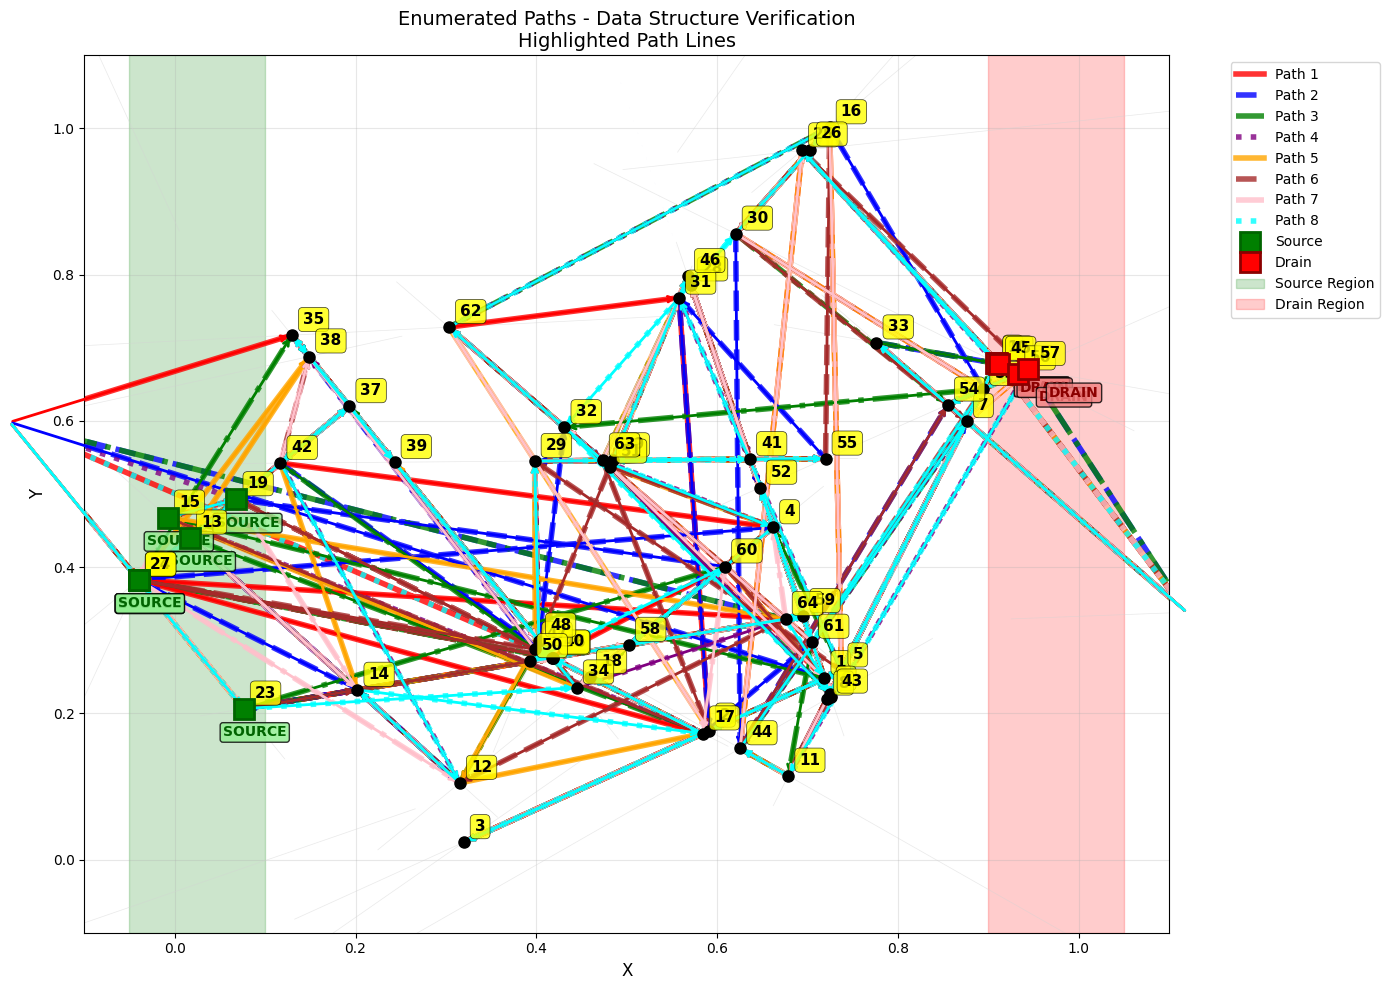


📊 PLOTTED PATHS INFORMATION:
   • Total paths: 8
   • Source Nodes: [13, 15, 19, 21, 22, 23, 24, 27]
   • Drain Nodes: [0, 9, 10, 45, 56, 57]
   • Path 1: 65 nodes - 13 → 12 → 14 → 15 → 19 → 21 → 27 → 37 → 42 → 4 → 18 → 34 → 58 → 60 → 20 → 23 → 40 → 50 → 59 → 64 → 24 → 17 → 36 → 47 → 22 → 35 → 38 → 39 → 48 → 29 → 41 → 49 → 55 → 63 → 1 → 6 → 28 → 43 → 46 → 52 → 61 → 32 → 51 → 62 → 31 → 2 → 3 → 5 → 16 → 26 → 30 → 53 → 54 → 56 → 57 → 7 → 8 → 9 → 10 → 11 → 44 → 25 → 45 → 0 → 33
     Status: PERCOLATING
   • Path 2: 65 nodes - 15 → 12 → 13 → 14 → 24 → 27 → 4 → 18 → 34 → 58 → 60 → 19 → 21 → 37 → 42 → 20 → 23 → 40 → 50 → 59 → 64 → 22 → 1 → 6 → 28 → 41 → 43 → 46 → 52 → 61 → 17 → 36 → 47 → 35 → 38 → 39 → 48 → 32 → 51 → 62 → 63 → 29 → 49 → 55 → 31 → 2 → 3 → 5 → 7 → 8 → 9 → 10 → 11 → 53 → 16 → 26 → 30 → 44 → 54 → 56 → 57 → 0 → 33 → 45 → 25
     Status: PERCOLATING
   • Path 3: 65 nodes - 19 → 13 → 17 → 18 → 20 → 21 → 27 → 36 → 37 → 42 → 47 → 12 → 14 → 15 → 1 → 2 → 3 → 5 → 4 → 34 → 58 → 60 → 23 →

In [75]:
import matplotlib.pyplot as plt
import numpy as np

def plot_enumerated_paths(N, points_1, points_2, intersections_points, path_nodes, path_pairs_of_edges):
    """
    Plot paths with enumerated nodes for visual verification of data structures
    """
    fig, ax = plt.subplots(figsize=(14, 10))

    # Plot all original lines in light gray
    for i in range(N):
        x_values = [points_1[i][0], points_2[i][0]]
        y_values = [points_1[i][1], points_2[i][1]]
        ax.plot(x_values, y_values, 'lightgray', linewidth=0.5, alpha=0.5)

    # Different colors and styles for each path
    colors = ['red', 'blue', 'green', 'purple', 'orange', 'brown', 'pink', 'cyan', 'magenta', 'darkred']
    line_styles = ['-', '--', '-.', ':']

    # Plot each path with different color and style
    for path_idx, nodes_in_path in enumerate(path_nodes):
        color = colors[path_idx % len(colors)]
        line_style = line_styles[path_idx % len(line_styles)]

        # Plot connections between consecutive nodes in path with highlighting
        path_x, path_y = [], []
        for i in range(len(nodes_in_path)):
            node_idx = nodes_in_path[i]
            if node_idx < len(intersections_points):
                path_x.append(intersections_points[node_idx][0])
                path_y.append(intersections_points[node_idx][1])

        # Plot the complete path line
        if len(path_x) > 1:
            ax.plot(path_x, path_y, color=color, linewidth=4, alpha=0.8,
                   linestyle=line_style, label=f'Path {path_idx + 1}')

            # Add arrows to show path direction
            for i in range(len(path_x) - 1):
                dx = path_x[i+1] - path_x[i]
                dy = path_y[i+1] - path_y[i]
                ax.annotate('', xy=(path_x[i+1], path_y[i+1]),
                           xytext=(path_x[i], path_y[i]),
                           arrowprops=dict(arrowstyle='->', color=color, lw=2))

    # Plot all intersection points
    for i, point in enumerate(intersections_points):
        ax.plot(point[0], point[1], 'ko', markersize=8, zorder=5)
        # Add node number next to the point
        ax.annotate(str(i), (point[0], point[1]), xytext=(8, 8),
                   textcoords='offset points', fontsize=11, fontweight='bold',
                   bbox=dict(boxstyle='round,pad=0.3', facecolor='yellow',
                            alpha=0.8, edgecolor='black', linewidth=0.5),
                   zorder=6)

    # Highlight source nodes with special markers
    source_plotted = False
    for i in boundary_condition_source:
        if i < len(intersections_points):
            ax.plot(intersections_points[i][0], intersections_points[i][1],
                   'gs', markersize=15, markeredgewidth=2, markeredgecolor='darkgreen',
                   label='Source' if not source_plotted else "", zorder=7)
            source_plotted = True
            # Add "SOURCE" text near the node
            ax.annotate('SOURCE', (intersections_points[i][0], intersections_points[i][1]),
                       xytext=(-15, -20), textcoords='offset points',
                       fontsize=10, fontweight='bold', color='darkgreen',
                       bbox=dict(boxstyle='round,pad=0.2', facecolor='lightgreen', alpha=0.8))

    # Highlight drain nodes with special markers
    drain_plotted = False
    for i in boundary_condition_drain:
        if i < len(intersections_points):
            ax.plot(intersections_points[i][0], intersections_points[i][1],
                   'rs', markersize=15, markeredgewidth=2, markeredgecolor='darkred',
                   label='Drain' if not drain_plotted else "", zorder=7)
            drain_plotted = True
            # Add "DRAIN" text near the node
            ax.annotate('DRAIN', (intersections_points[i][0], intersections_points[i][1]),
                       xytext=(15, -20), textcoords='offset points',
                       fontsize=10, fontweight='bold', color='darkred',
                       bbox=dict(boxstyle='round,pad=0.2', facecolor='lightcoral', alpha=0.8))


    # Add source and drain regions with semi-transparent rectangles
    ax.axvspan(-0.05, 0.1, alpha=0.2, color='green', label='Source Region')
    ax.axvspan(0.9, 1.05, alpha=0.2, color='red', label='Drain Region')

    ax.set_xlim(-0.1, 1.1)
    ax.set_ylim(-0.1, 1.1)
    ax.set_xlabel('X', fontsize=12)
    ax.set_ylabel('Y', fontsize=12)
    ax.set_title('Enumerated Paths - Data Structure Verification\nHighlighted Path Lines', fontsize=14)
    ax.grid(True, alpha=0.3)

    # Improve legend
    ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=10)

    plt.tight_layout()
    plt.show()

    # Print information about plotted paths
    print(f"\n📊 PLOTTED PATHS INFORMATION:")
    print(f"   • Total paths: {len(path_nodes)}")
    print(f"   • Source Nodes: {boundary_condition_source}")
    print(f"   • Drain Nodes: {boundary_condition_drain}")

    for path_idx, nodes in enumerate(path_nodes):
        print(f"   • Path {path_idx + 1}: {len(nodes)} nodes - {' → '.join(map(str, nodes))}")
        if path_idx < len(all_path_perc):
            perc_status = "PERCOLATING" if all_path_perc[path_idx] else "NON-PERCOLATING"
            print(f"     Status: {perc_status}")
    print()

# Plot paths with enumerated nodes
plot_enumerated_paths(N, points_1, points_2, intersections_points, path_nodes, path_pairs_of_edges)

In [76]:
# Detailed reference table for verification
print("=" * 80)
print("REFERENCE TABLE - DATA STRUCTURE VERIFICATION")
print("=" * 80)

for path_idx in range(len(path_nodes)):
    print(f"\n🔹 PATH {path_idx + 1}:")

    # Show node sequence
    print(f"   Node sequence: {' → '.join(map(str, path_nodes[path_idx]))}")

    # Show node coordinates
    node_coords = []
    for node_idx in path_nodes[path_idx]:
        if node_idx < len(intersections_points):
            coord = intersections_points[node_idx]
            node_coords.append(f"({coord[0]:.3f}, {coord[1]:.3f})")
        else:
            node_coords.append("(N/A)")
    print(f"   Coordinates:  {' → '.join(node_coords)}")

    # Show corresponding edges
    if path_idx < len(path_edges):
        print(f"   Edges:        {path_edges[path_idx]}")

        # Show edge details
        if len(path_edges[path_idx]) > 0:
            edge_details = []
            for edge_idx in path_edges[path_idx]:
                if edge_idx < len(graph):
                    edge = graph[edge_idx]
                    edge_details.append(f"E{edge_idx}({edge[0]}↔{edge[1]})")
                else:
                    edge_details.append(f"E{edge_idx}(N/A)")
            print(f"   Edge details: {' → '.join(edge_details)}")

    # Show edge pairs
    if path_idx < len(path_pairs_of_edges):
        print(f"   Edge pairs:   {path_pairs_of_edges[path_idx]}")

        # Show corresponding nodes for pairs
        if path_idx < len(edge_nodes):
            print(f"   Pair nodes:   {edge_nodes[path_idx]}")

    # Show percolation information
    if path_idx < len(all_path_perc):
        perc_status = "YES" if all_path_perc[path_idx] else "NO"
        print(f"   Percolation:  {perc_status}")

    print("-" * 80)

# Additional graph information
print(f"\n📊 GRAPH STATISTICS:")
print(f"   Total intersection points: {len(intersections_points)}")
print(f"   Total graph edges: {len(graph)}")
print(f"   Source nodes: {boundary_condition_source}")
print(f"   Drain nodes: {boundary_condition_drain}")
print(f"   Total found paths: {len(path_nodes)}")

# Integrity verification
print(f"\n🔍 INTEGRITY VERIFICATION:")
for i, nodes in enumerate(path_nodes):
    if i < len(path_edges):
        expected_edges = len(nodes) - 1 if len(nodes) > 0 else 0
        actual_edges = len(path_edges[i])
        status = "✓" if actual_edges == expected_edges else "✗"
        print(f"   Path {i+1}: {status} {actual_edges} edges for {len(nodes)} nodes (expected: {expected_edges})")

print("=" * 80)

REFERENCE TABLE - DATA STRUCTURE VERIFICATION

🔹 PATH 1:
   Node sequence: 13 → 12 → 14 → 15 → 19 → 21 → 27 → 37 → 42 → 4 → 18 → 34 → 58 → 60 → 20 → 23 → 40 → 50 → 59 → 64 → 24 → 17 → 36 → 47 → 22 → 35 → 38 → 39 → 48 → 29 → 41 → 49 → 55 → 63 → 1 → 6 → 28 → 43 → 46 → 52 → 61 → 32 → 51 → 62 → 31 → 2 → 3 → 5 → 16 → 26 → 30 → 53 → 54 → 56 → 57 → 7 → 8 → 9 → 10 → 11 → 44 → 25 → 45 → 0 → 33
   Coordinates:  (0.017, 0.440) → (0.315, 0.105) → (0.202, 0.232) → (-0.008, 0.468) → (0.068, 0.493) → (-0.040, 0.383) → (-0.040, 0.383) → (0.193, 0.620) → (0.117, 0.542) → (0.662, 0.454) → (0.459, 0.250) → (0.445, 0.235) → (0.502, 0.294) → (0.609, 0.401) → (0.417, 0.276) → (0.076, 0.206) → (0.418, 0.276) → (0.393, 0.271) → (0.695, 0.333) → (0.676, 0.329) → (-0.040, 0.382) → (0.584, 0.172) → (0.419, 0.275) → (0.399, 0.288) → (-0.182, 0.598) → (0.130, 0.717) → (0.149, 0.688) → (0.243, 0.544) → (0.403, 0.299) → (0.398, 0.545) → (0.636, 0.547) → (0.484, 0.546) → (0.720, 0.548) → (0.473, 0.546) → (0.719, 0.24

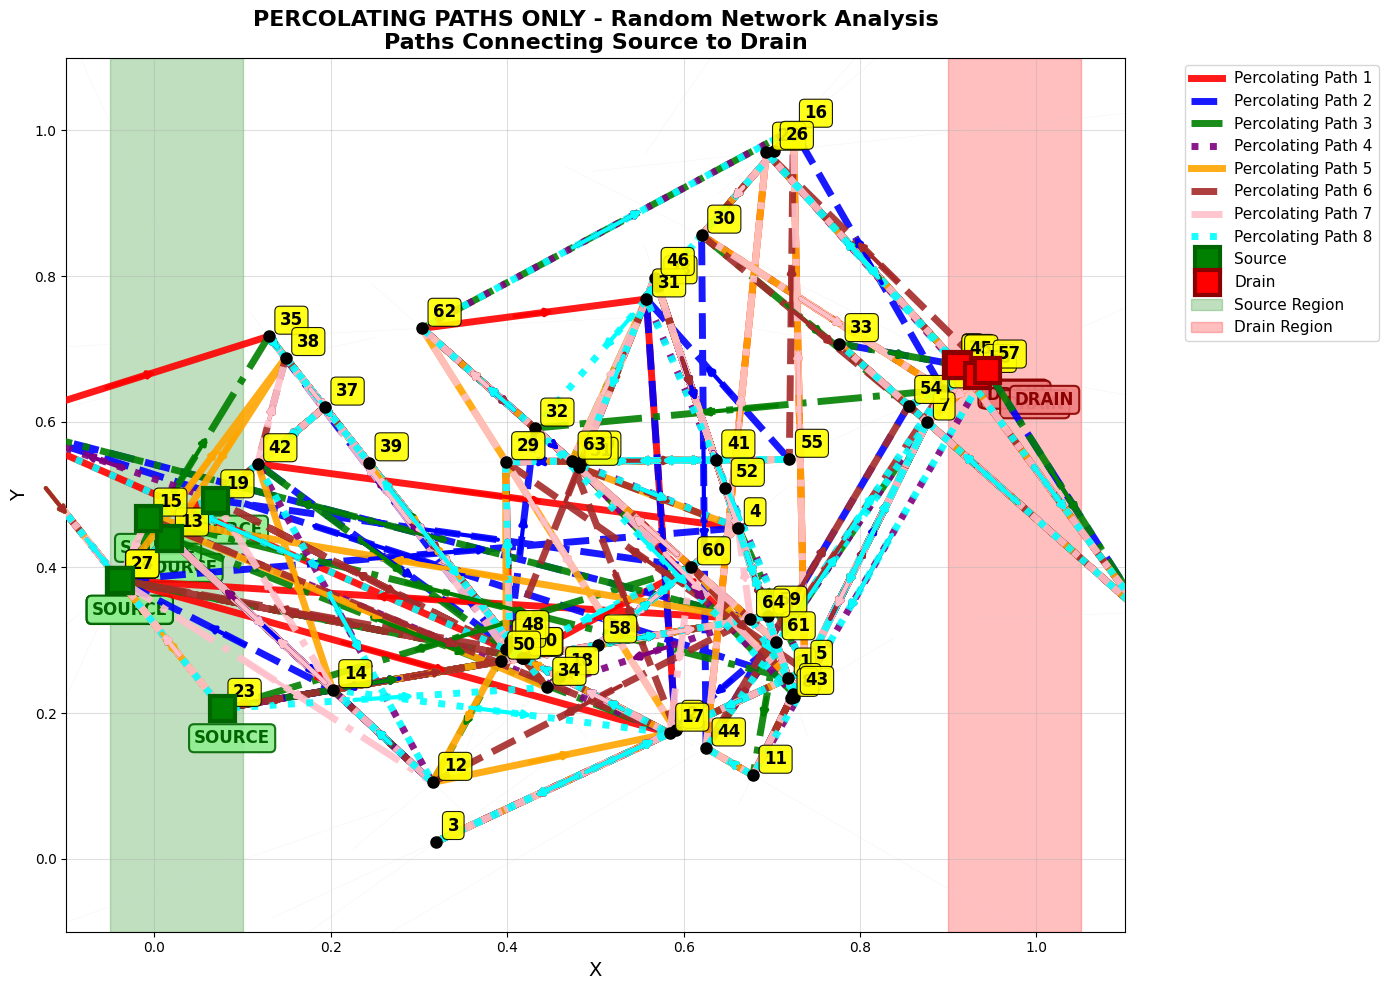


🔥 PERCOLATING PATHS ANALYSIS:
   • Total paths found: 8
   • Percolating paths: 8
   • Non-percolating paths: 0
   • Percolation ratio: 100.0%

   🟢 PERCOLATING PATH 1:
      • Nodes: 13 → 12 → 14 → 15 → 19 → 21 → 27 → 37 → 42 → 4 → 18 → 34 → 58 → 60 → 20 → 23 → 40 → 50 → 59 → 64 → 24 → 17 → 36 → 47 → 22 → 35 → 38 → 39 → 48 → 29 → 41 → 49 → 55 → 63 → 1 → 6 → 28 → 43 → 46 → 52 → 61 → 32 → 51 → 62 → 31 → 2 → 3 → 5 → 16 → 26 → 30 → 53 → 54 → 56 → 57 → 7 → 8 → 9 → 10 → 11 → 44 → 25 → 45 → 0 → 33
      • Total nodes: 65
      • Connects source: ✓
      • Connects drain: ✓
      • Path coordinates: (0.017, 0.440) → (0.315, 0.105) → (0.202, 0.232) → (-0.008, 0.468) → (0.068, 0.493) → (-0.040, 0.383) → (-0.040, 0.383) → (0.193, 0.620) → (0.117, 0.542) → (0.662, 0.454) → (0.459, 0.250) → (0.445, 0.235) → (0.502, 0.294) → (0.609, 0.401) → (0.417, 0.276) → (0.076, 0.206) → (0.418, 0.276) → (0.393, 0.271) → (0.695, 0.333) → (0.676, 0.329) → (-0.040, 0.382) → (0.584, 0.172) → (0.419, 0.275) → (0.3

In [77]:
import matplotlib.pyplot as plt
import numpy as np

def plot_percolating_paths_only(N, points_1, points_2, intersections_points, path_nodes, all_path_perc):
    """
    Plot only the percolating paths with enumerated nodes for visual verification
    """
    fig, ax = plt.subplots(figsize=(14, 10))

    # Plot all original lines in very light gray as background
    for i in range(N):
        x_values = [points_1[i][0], points_2[i][0]]
        y_values = [points_1[i][1], points_2[i][1]]
        ax.plot(x_values, y_values, 'lightgray', linewidth=0.3, alpha=0.3)

    # Colors and styles for percolating paths only
    colors = ['red', 'blue', 'green', 'purple', 'orange', 'brown', 'pink', 'cyan', 'magenta', 'darkred']
    line_styles = ['-', '--', '-.', ':']

    percolating_count = 0

    # Plot only percolating paths with highlighting
    for path_idx, nodes_in_path in enumerate(path_nodes):
        # Check if this path is percolating
        if path_idx < len(all_path_perc) and all_path_perc[path_idx]:
            color = colors[percolating_count % len(colors)]
            line_style = line_styles[percolating_count % len(line_styles)]

            # Get coordinates for the percolating path
            path_x, path_y = [], []
            for i in range(len(nodes_in_path)):
                node_idx = nodes_in_path[i]
                if node_idx < len(intersections_points):
                    path_x.append(intersections_points[node_idx][0])
                    path_y.append(intersections_points[node_idx][1])

            # Plot the complete percolating path line with emphasis
            if len(path_x) > 1:
                ax.plot(path_x, path_y, color=color, linewidth=5, alpha=0.9,
                       linestyle=line_style, label=f'Percolating Path {percolating_count + 1}',
                       zorder=4)

                # Add arrows to show path direction with larger arrows
                for i in range(len(path_x) - 1):
                    dx = path_x[i+1] - path_x[i]
                    dy = path_y[i+1] - path_y[i]
                    # Add arrow at the middle of each segment
                    mid_x = (path_x[i] + path_x[i+1]) / 2
                    mid_y = (path_y[i] + path_y[i+1]) / 2
                    ax.annotate('', xy=(mid_x + dx*0.1, mid_y + dy*0.1),
                               xytext=(mid_x - dx*0.1, mid_y - dy*0.1),
                               arrowprops=dict(arrowstyle='->', color=color, lw=3),
                               zorder=5)

            percolating_count += 1

    # Plot all intersection points
    for i, point in enumerate(intersections_points):
        ax.plot(point[0], point[1], 'ko', markersize=8, zorder=6)
        # Add node number next to the point with enhanced visibility
        ax.annotate(str(i), (point[0], point[1]), xytext=(8, 8),
                   textcoords='offset points', fontsize=12, fontweight='bold',
                   bbox=dict(boxstyle='round,pad=0.3', facecolor='yellow',
                            alpha=0.9, edgecolor='black', linewidth=0.8),
                   zorder=7)

    # Highlight source nodes with enhanced markers
    source_plotted = False
    for i in boundary_condition_source:
        if i < len(intersections_points):
            ax.plot(intersections_points[i][0], intersections_points[i][1],
                   'gs', markersize=18, markeredgewidth=3, markeredgecolor='darkgreen',
                   label='Source' if not source_plotted else "", zorder=8)
            source_plotted = True
            # Add enhanced "SOURCE" text
            ax.annotate('SOURCE', (intersections_points[i][0], intersections_points[i][1]),
                       xytext=(-20, -25), textcoords='offset points',
                       fontsize=12, fontweight='bold', color='darkgreen',
                       bbox=dict(boxstyle='round,pad=0.3', facecolor='lightgreen',
                               alpha=0.9, edgecolor='darkgreen', linewidth=1.5))

    # Highlight drain nodes with enhanced markers
    drain_plotted = False
    for i in boundary_condition_drain:
        if i < len(intersections_points):
            ax.plot(intersections_points[i][0], intersections_points[i][1],
                   'rs', markersize=18, markeredgewidth=3, markeredgecolor='darkred',
                   label='Drain' if not drain_plotted else "", zorder=8)
            drain_plotted = True
            # Add enhanced "DRAIN" text
            ax.annotate('DRAIN', (intersections_points[i][0], intersections_points[i][1]),
                       xytext=(20, -25), textcoords='offset points',
                       fontsize=12, fontweight='bold', color='darkred',
                       bbox=dict(boxstyle='round,pad=0.3', facecolor='lightcoral',
                               alpha=0.9, edgecolor='darkred', linewidth=1.5))

    # Add enhanced source and drain regions
    ax.axvspan(-0.05, 0.1, alpha=0.25, color='green', label='Source Region', zorder=1)
    ax.axvspan(0.9, 1.05, alpha=0.25, color='red', label='Drain Region', zorder=1)

    ax.set_xlim(-0.1, 1.1)
    ax.set_ylim(-0.1, 1.1)
    ax.set_xlabel('X', fontsize=14)
    ax.set_ylabel('Y', fontsize=14)
    ax.set_title('PERCOLATING PATHS ONLY - Random Network Analysis\nPaths Connecting Source to Drain',
                fontsize=16, fontweight='bold')
    ax.grid(True, alpha=0.4)

    # Enhanced legend
    ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=11)

    plt.tight_layout()
    plt.show()

    # Print detailed information about percolating paths
    print(f"\n🔥 PERCOLATING PATHS ANALYSIS:")
    print(f"   • Total paths found: {len(path_nodes)}")
    print(f"   • Percolating paths: {percolating_count}")
    print(f"   • Non-percolating paths: {len(path_nodes) - percolating_count}")
    print(f"   • Percolation ratio: {percolating_count/len(path_nodes)*100:.1f}%" if len(path_nodes) > 0 else "   • Percolation ratio: 0%")

    percolating_path_count = 0
    for path_idx, nodes in enumerate(path_nodes):
        if path_idx < len(all_path_perc) and all_path_perc[path_idx]:
            percolating_path_count += 1
            print(f"\n   🟢 PERCOLATING PATH {percolating_path_count}:")
            print(f"      • Nodes: {' → '.join(map(str, nodes))}")
            print(f"      • Total nodes: {len(nodes)}")

            # Check if path connects source to drain regions
            source_connected = any(node in boundary_condition_source for node in nodes)
            drain_connected = any(node in boundary_condition_drain for node in nodes)
            print(f"      • Connects source: {'✓' if source_connected else '✗'}")
            print(f"      • Connects drain: {'✓' if drain_connected else '✗'}")

            # Show path coordinates
            coords = []
            for node in nodes:
                if node < len(intersections_points):
                    coord = intersections_points[node]
                    coords.append(f"({coord[0]:.3f}, {coord[1]:.3f})")
            print(f"      • Path coordinates: {' → '.join(coords)}")

    if percolating_count == 0:
        print("\n   ⚠️ NO PERCOLATING PATHS FOUND")
        print("   • The network does not show percolation between source and drain")
        print("   • Try different network parameters (a, N) or regenerate the network")

    print(f"\n   📊 NETWORK PERCOLATION STATUS:")
    if percolating_count > 0:
        print(f"   ✅ NETWORK PERCOLATES - {percolating_count} active path(s)")
        print(f"   🔗 Connectivity established between source and drain regions")
    else:
        print(f"   ❌ NETWORK DOES NOT PERCOLATE")
        print(f"   🚫 No connectivity between source and drain regions")
    print()

# Plot only percolating paths
plot_percolating_paths_only(N, points_1, points_2, intersections_points, path_nodes, all_path_perc)